# N112: four-output predictor and calibrated health constraints

Status: **stopped**. Active: **preparation / offline work**.

Three NEW matched 91,968-image runs, each restoring the ORIGINAL image-model,
optimizer and RNG parent. Actions are {0,1/8,1/4} of ORIGINAL nominal LR.
All 4,032 offline images stay excluded from online training.

| Run | Cost predictor | Health constraints | Horizon |
| --- | --- | --- | ---: |
| A · Unconstrained H1 | Direct delta-J head | None | 1 |
| B · Calibrated H1 | Identical head/fit | Conservative RankMe/variance bounds | 1 |
| C · Calibrated H2 MPC | Identical head/fit | Same bounds at BOTH predicted steps | 2 |

Four-output quadratic ridge predicts [delta-J, delta-RankMe, delta-reconstruction,
delta-variance] using the same 88 rich inputs and TRAIN-only transforms. Collect
NEW matched offline responses at the deployed rates, including actual nine-path
two-step trials for validation/test. Every offline split restores the original
parent independently. Fit only TRAIN; calibrate only VALIDATION; TEST is readout
only. No old online predictor or image weights transfer.

Direct-J predicts cost separately from health trajectories. H2 accumulates direct
J changes, minimizes summed next-two predicted J, executes first action only and
replans. Propagate predicted metric/history/action inputs; hold other context fixed.
No future images or imagined adaptation are used by the predictor.

Calibration uses one-sided per-metric residuals, maxima over ALL actions/sequences,
and Bonferroni allocation across rank/variance and horizons 1/2 for nominal 95%
joint coverage. These are empirical bounds, NOT a formal online safety guarantee.
Frozen offline margins may widen using ONLY past chosen-action residuals (last512,
minimum80 scores). Trivial skip outcomes do not dilute positive-update scores.

Causal floors retain90% of peak past smoothed RankMe and80% of peak past smoothed
variance. Start anchors at the ORIGINAL parent; smooth with256-successful-update
half-life. Both arms plan against the already-known floors, never future anchors.
A computes identical shadow diagnostics without applying the filter.

5% exploration is restricted to first actions with feasible continuation; no
exploration during recovery. When already outside feasibility, allow only an
explicit mean-predicted repair that does not further worsen a breached metric;
otherwise skip. Recovery relaxations and actual health breaches are logged.
Only successful actually applied positive actions update the four-head ridge.
Keep fixed original J, alpha1 (intercepts .1), zero-centered regularizer,256-update
forgetting, paired seeds, rollback/cooldown and384-arrival readouts/checkpoints.
Labels enter task readouts only. Source history/audit were previously inspected.

| Arm | Saved images | Plant updates | Predictor updates | Available late probe (%) | Recorded time (min) |
| --- | ---: | ---: | ---: | ---: | ---: |
| A · Unconstrained H1 | 91,968 | 8,943 | 8,943 | 62.711 | 106.35 |
| B · Calibrated H1 | 91,968 | 1,642 | 1,642 | 63.667 | 72.24 |
| C · Calibrated H2 MPC | 42,869 | 0 | 0 | 60.583 (partial) | 17.69 |

Common coverage across all three arms: **42,869**. Available table means use each arm's saved coverage; primary comparisons use common scheduled30k--91,968 checkpoints.

## Positive-update one-step forecast RMSE

| Arm | Output | Active model | Frozen shadow, same states/actions | Persistence | Positive updates |
| --- | --- | ---: | ---: | ---: | ---: |
| A · Unconstrained H1 | RankMe | 0.0040187 | 0.00552659 | 0.00700005 | 8,943 |
| A · Unconstrained H1 | Reconstruction loss | 0.000341909 | 0.00107211 | 0.000584911 | 8,943 |
| A · Unconstrained H1 | Variance | 1.59846e-05 | 2.89693e-05 | 2.896e-05 | 8,943 |
| B · Calibrated H1 | RankMe | 0.00398043 | 0.00488507 | 0.00723487 | 1,642 |
| B · Calibrated H1 | Reconstruction loss | 0.000510533 | 0.000763318 | 0.000927143 | 1,642 |
| B · Calibrated H1 | Variance | 2.00954e-05 | 3.14293e-05 | 3.99297e-05 | 1,642 |

RMSE is in native metric units. Different policies visit different states; the frozen-shadow comparison is paired within each plant trajectory. Per-action and two-step numbers/counts are saved in comparison.json.


## Balanced audit linear accuracy (%)

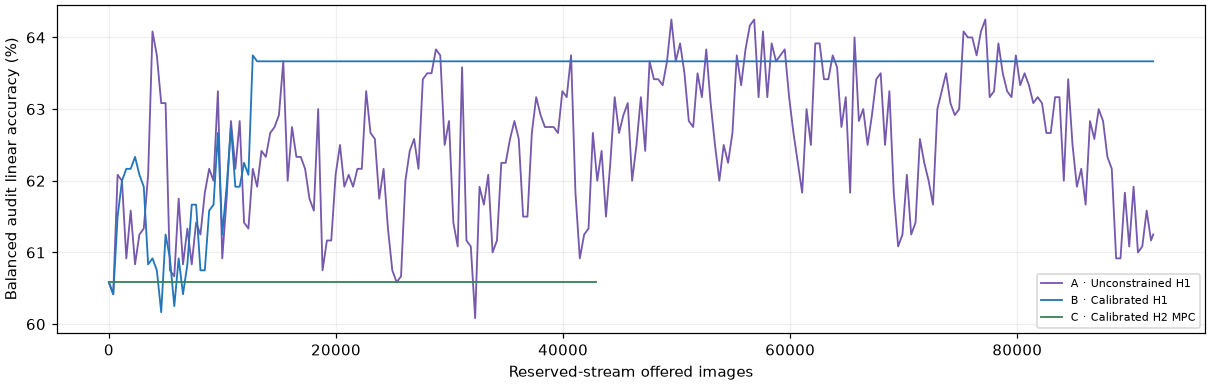



## RankMe

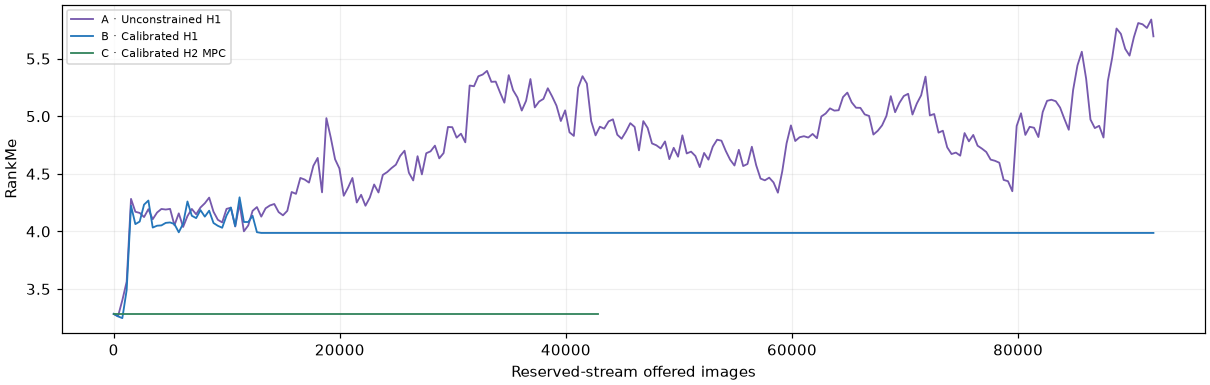



## Fixed-bank reconstruction loss

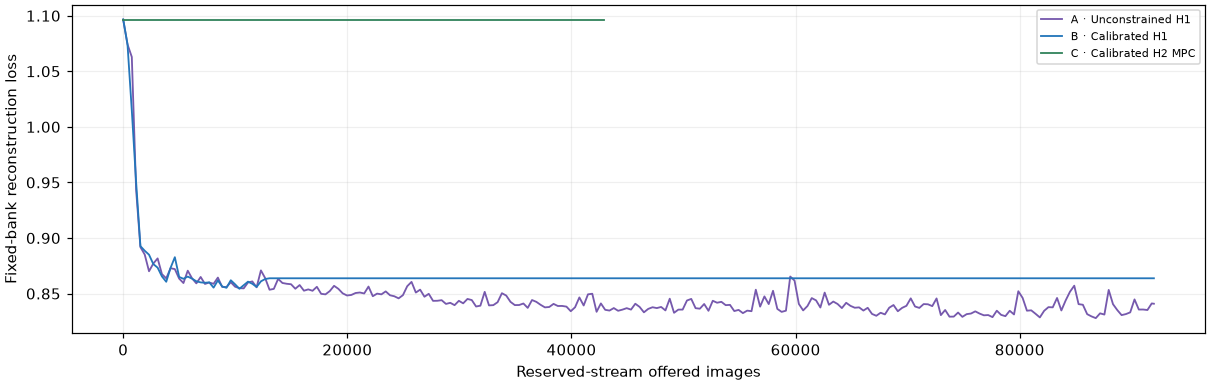



## Variance

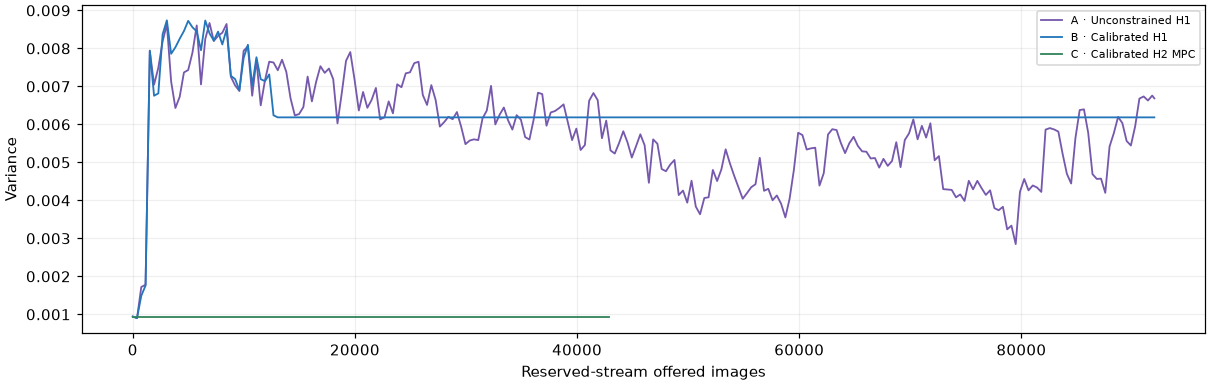



## Original fixed-bank J

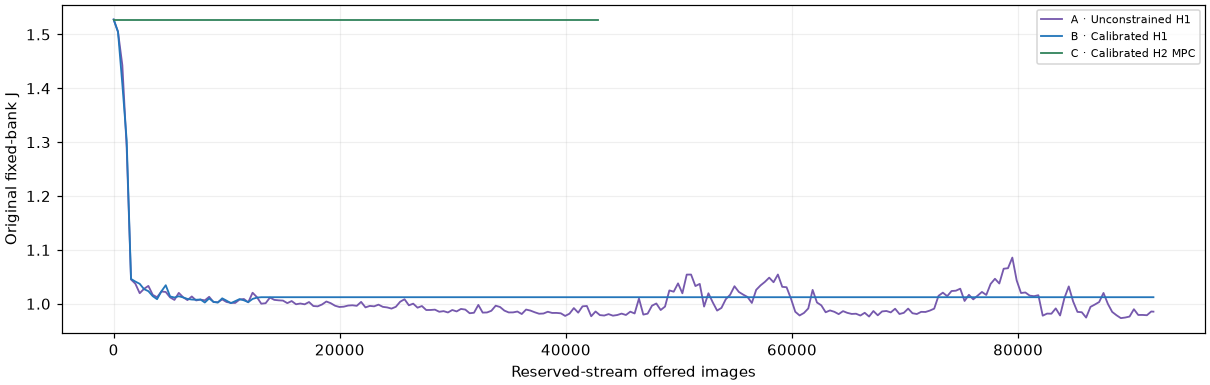



## Covariance

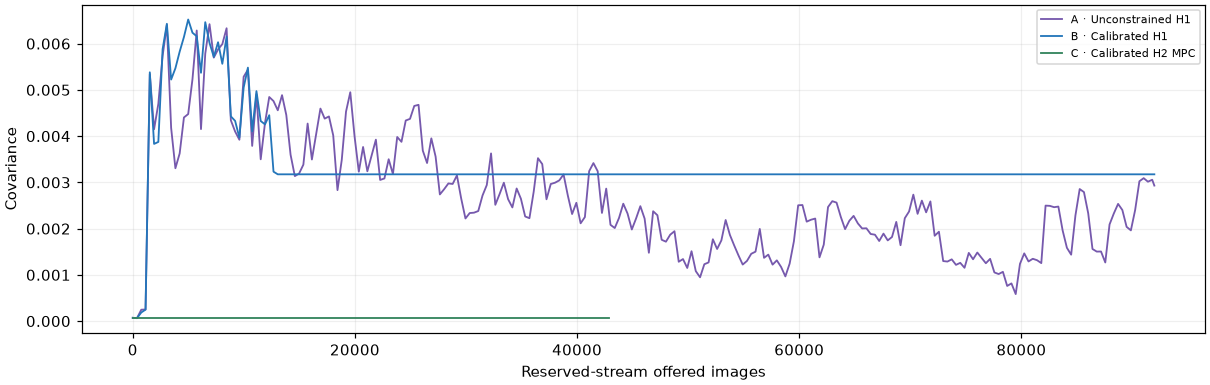



## Actual plant outputs and one-step forecasts

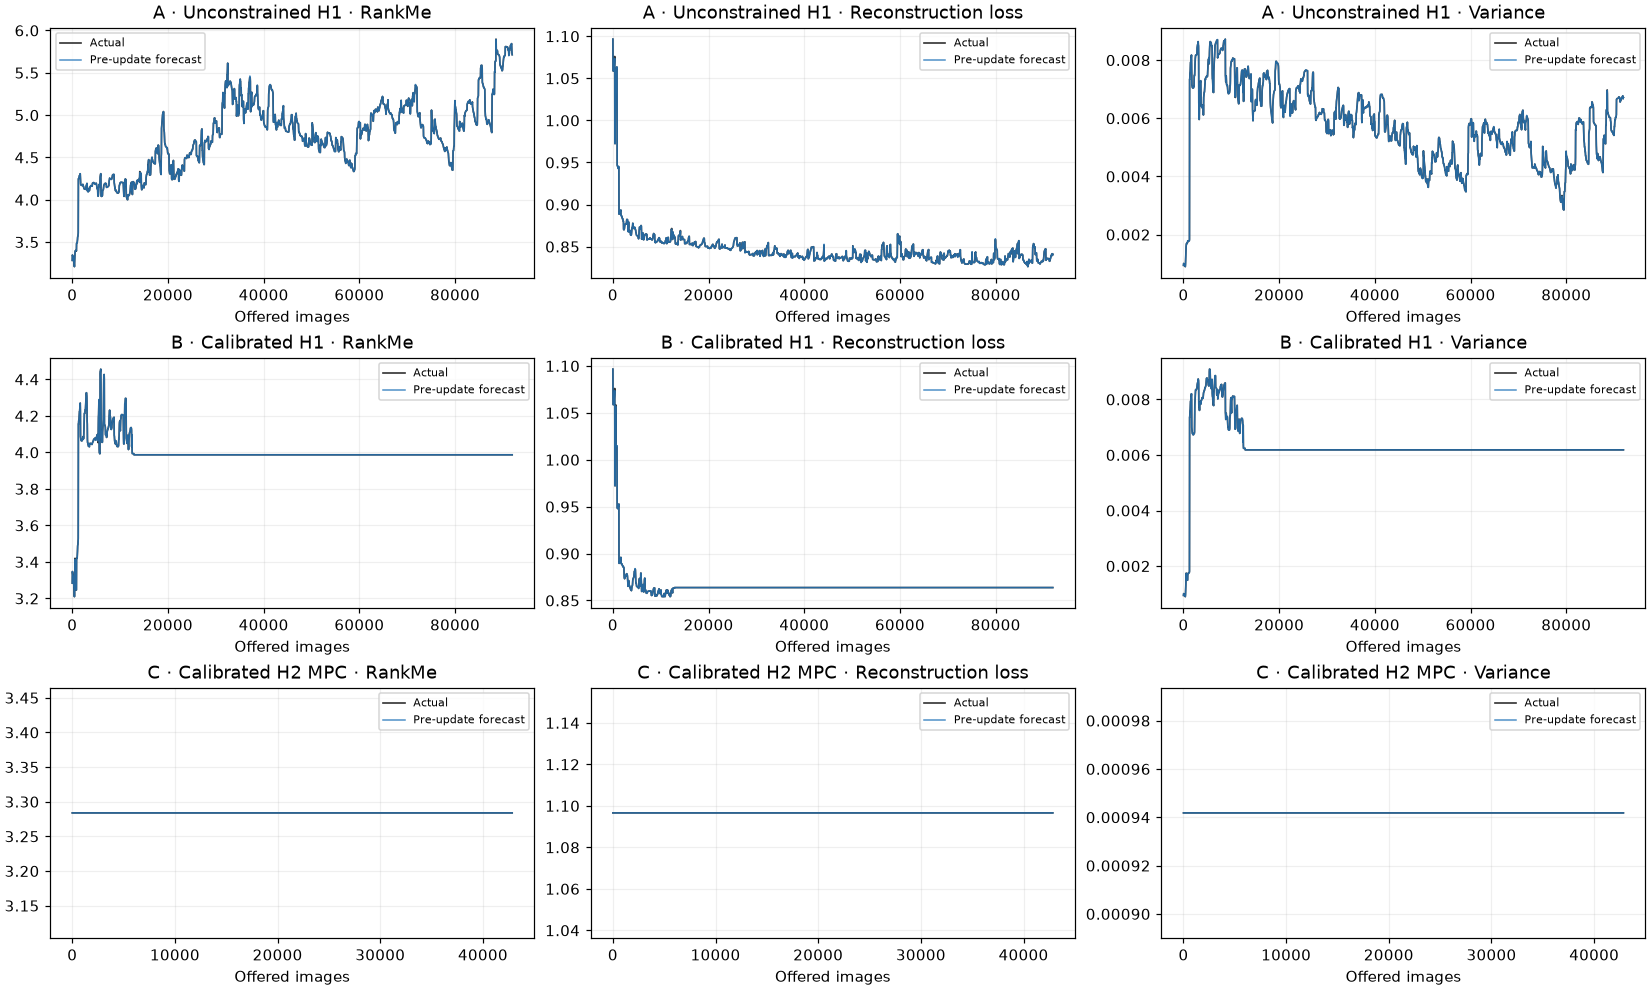

Display subsamples every32 arrivals; RMSE uses all successful positive updates and excludes identity skips.

## One-step positive-update RMSE

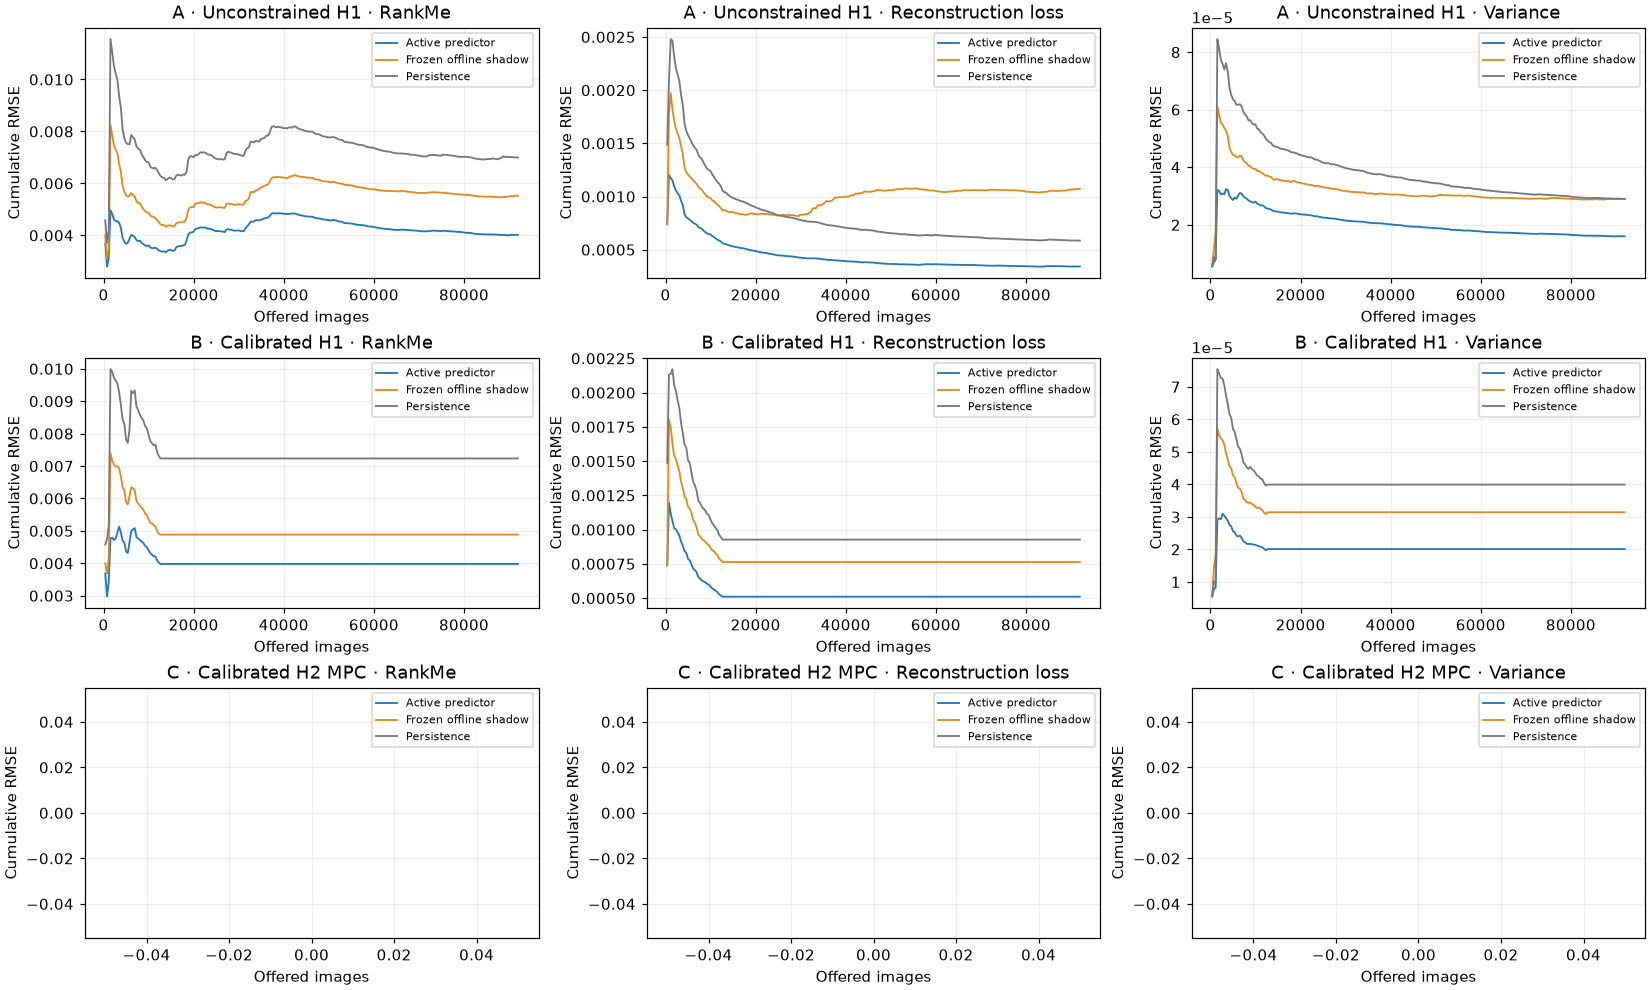



## Two-step nontrivial-window RMSE

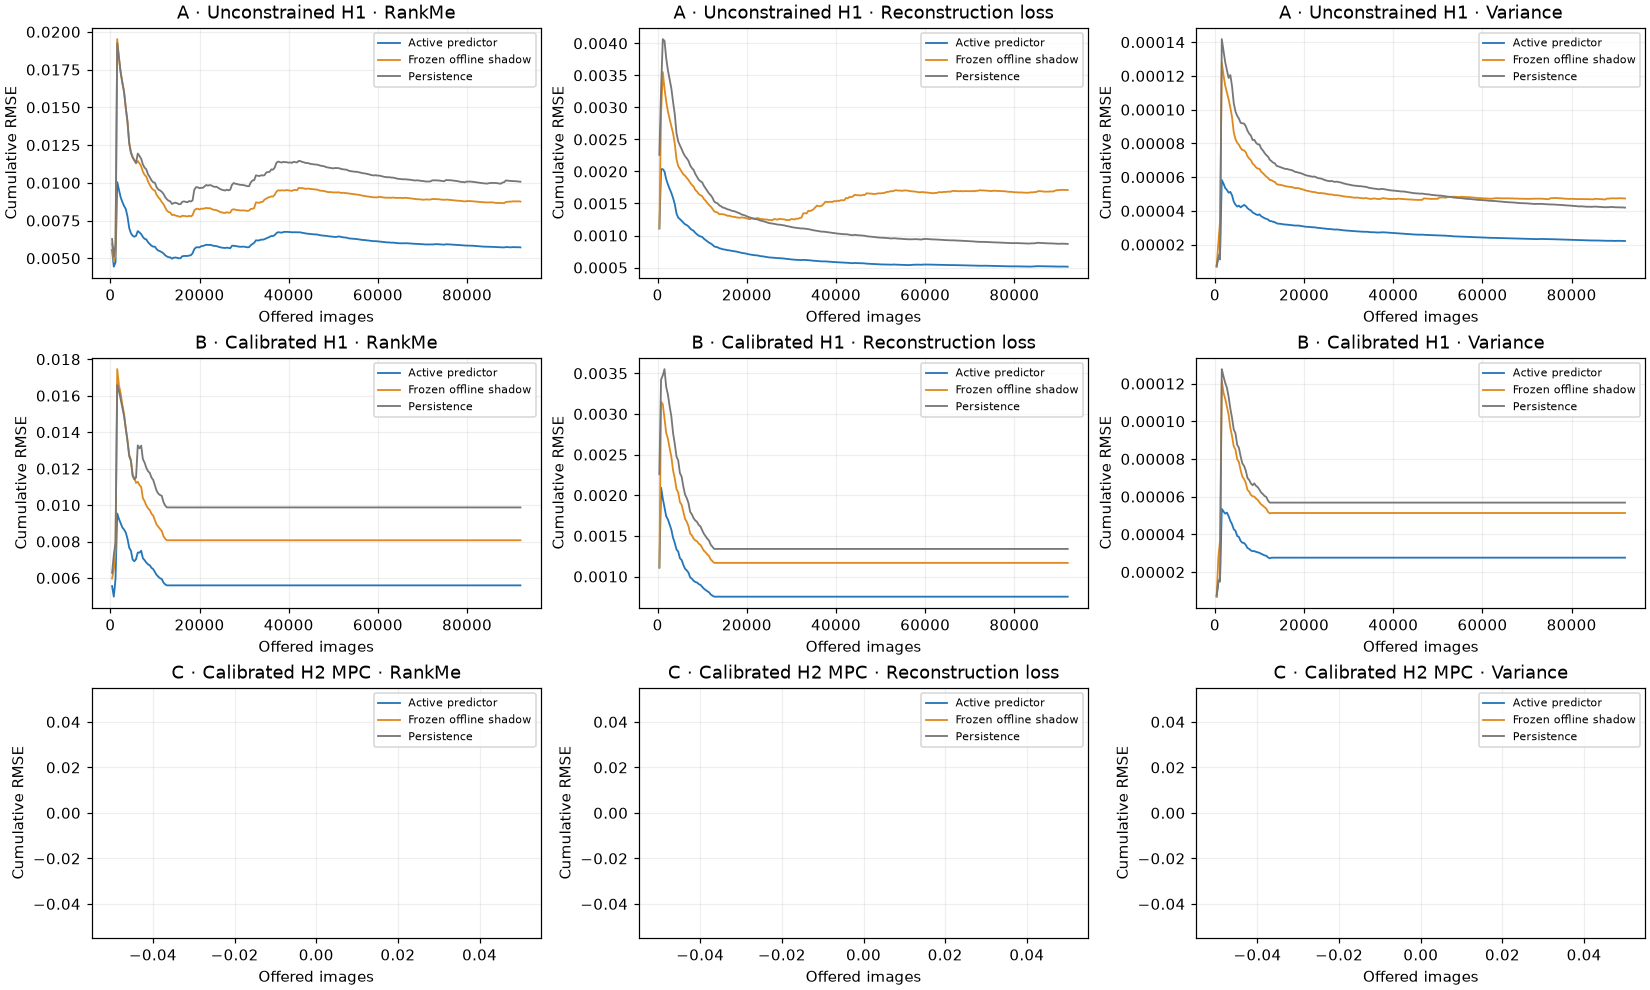



## Plant update and rate budgets

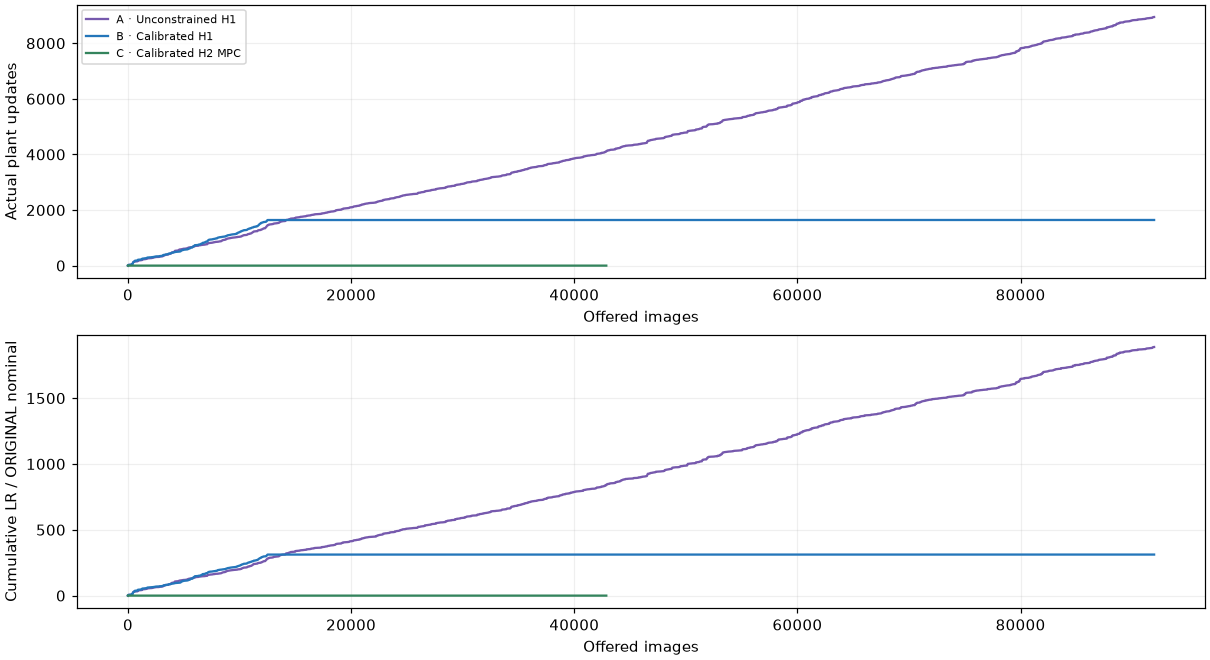



## Transition-model adaptation

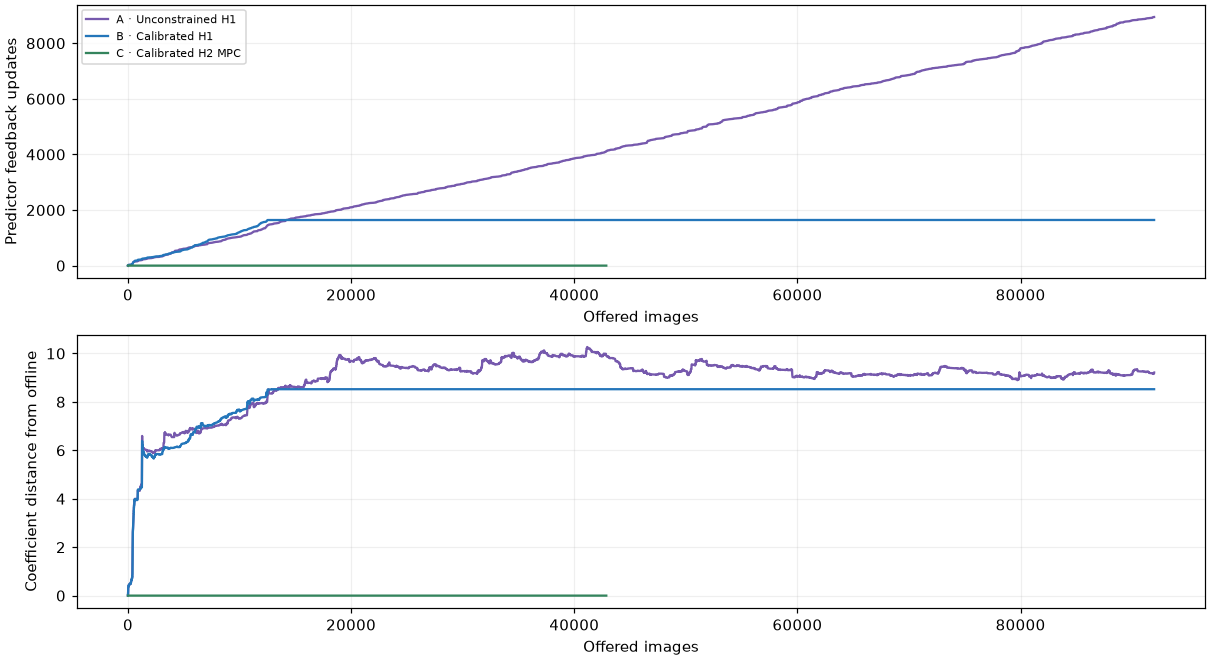



## Executed learning-rate actions

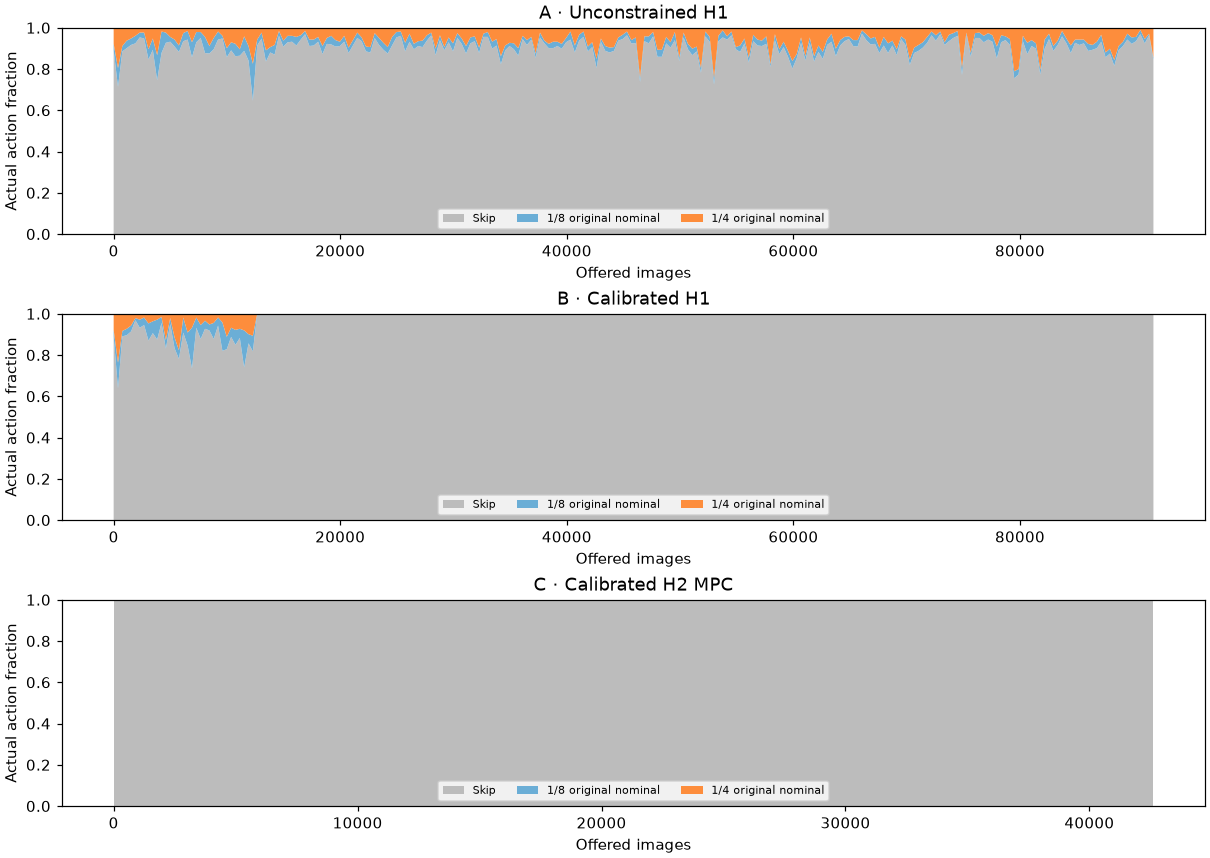



## Actual trained-image losses

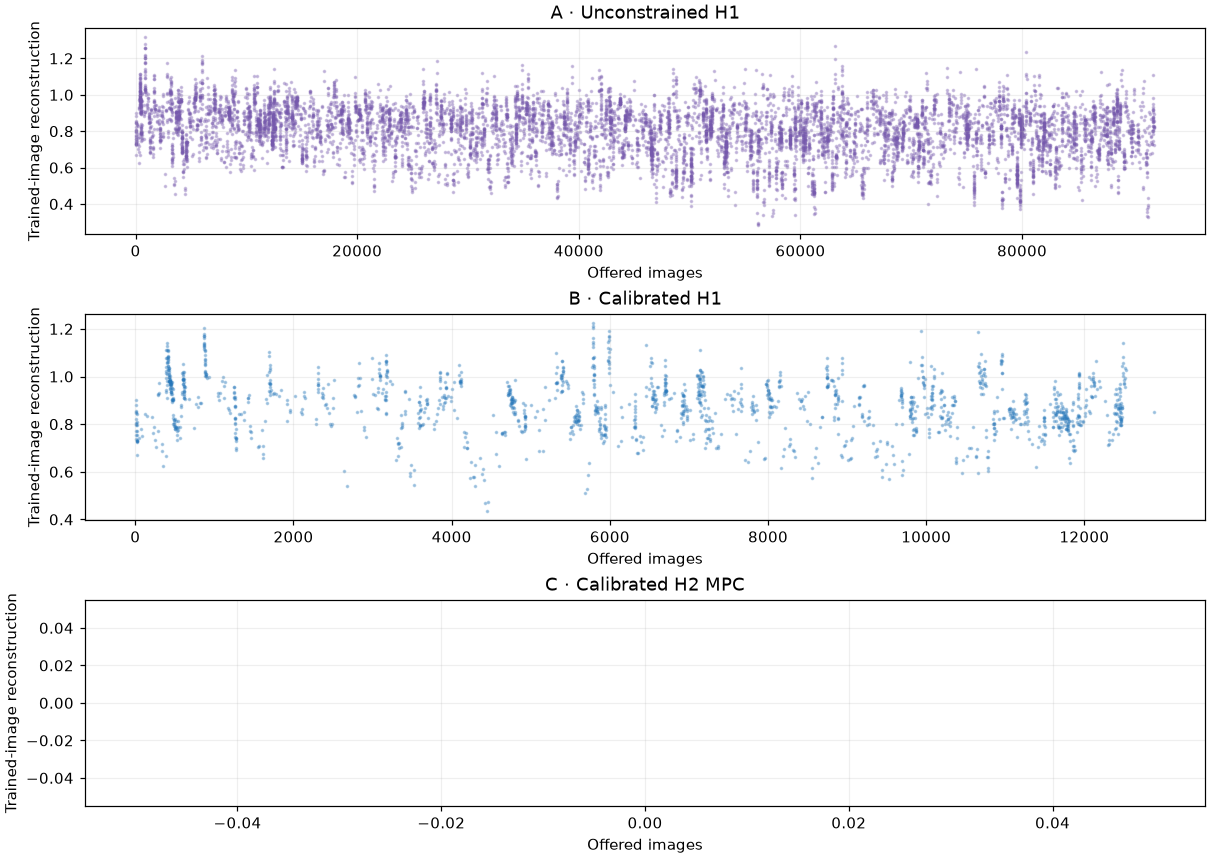



## Audit: linear task metrics

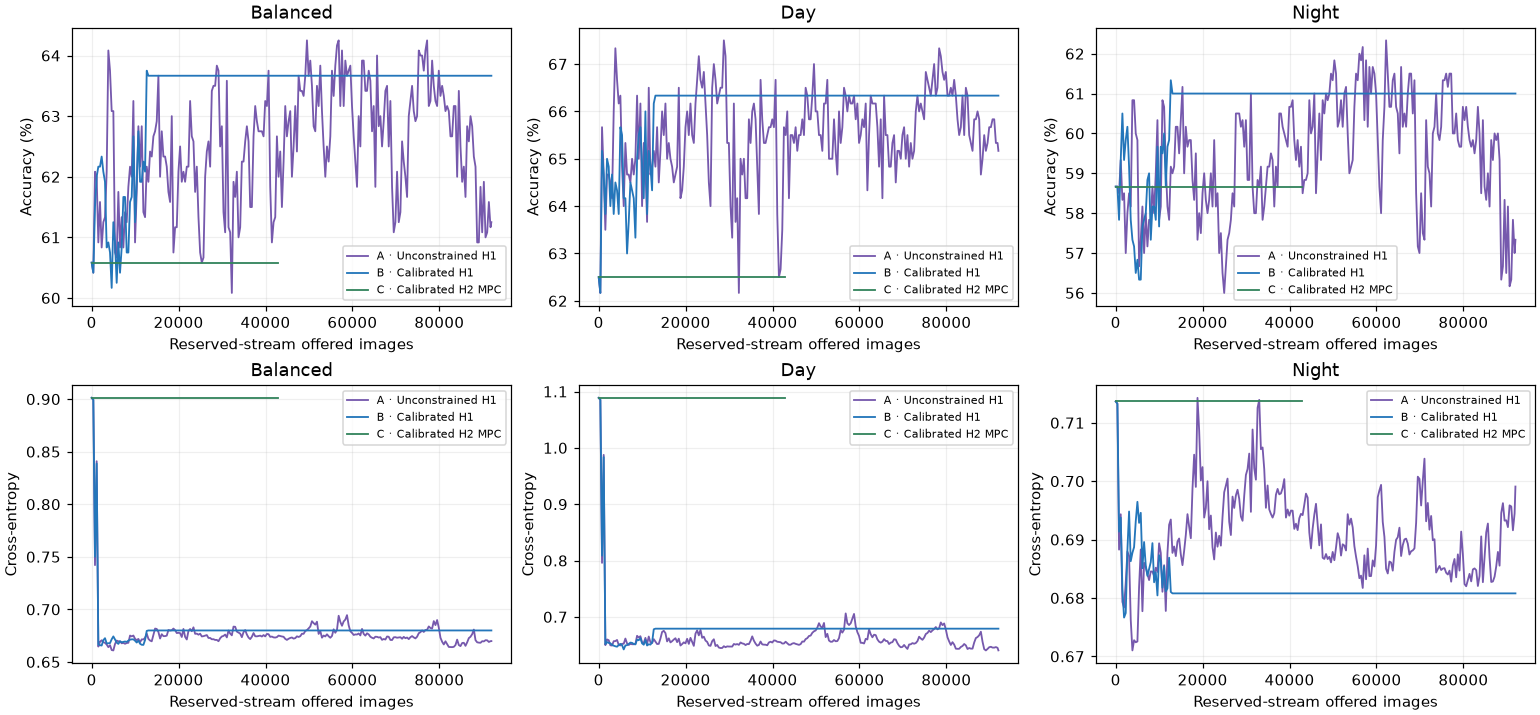



## Audit: knn task metrics

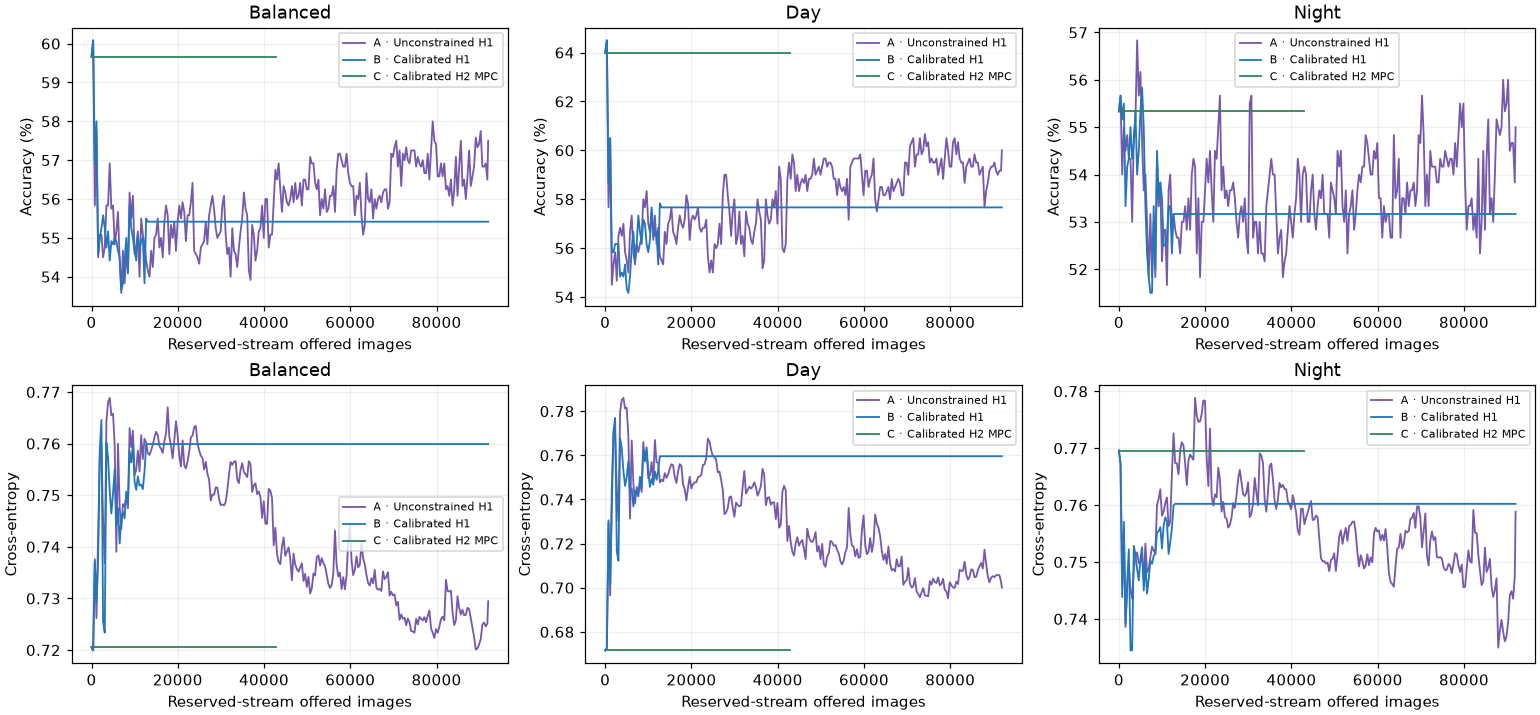



## Previous evaluation: linear task metrics

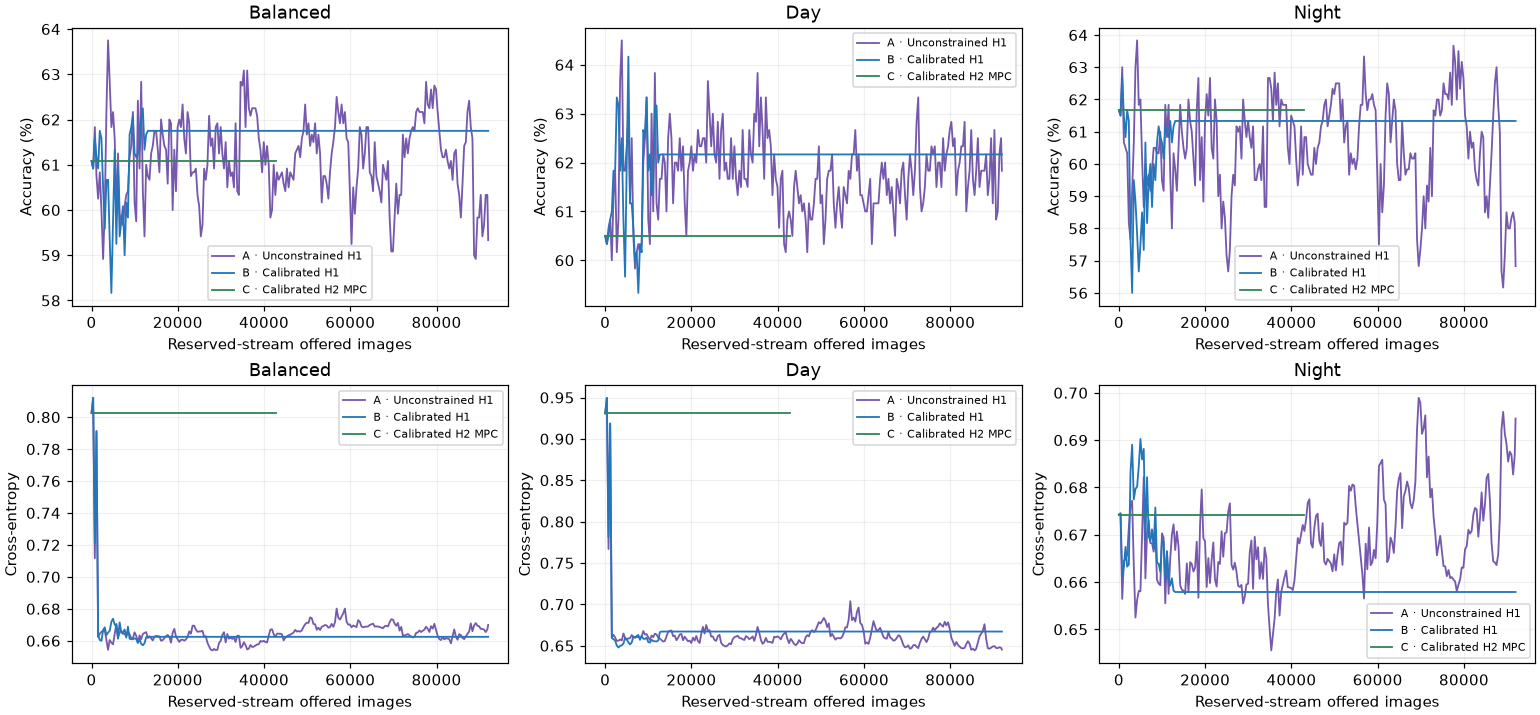



## Previous evaluation: knn task metrics

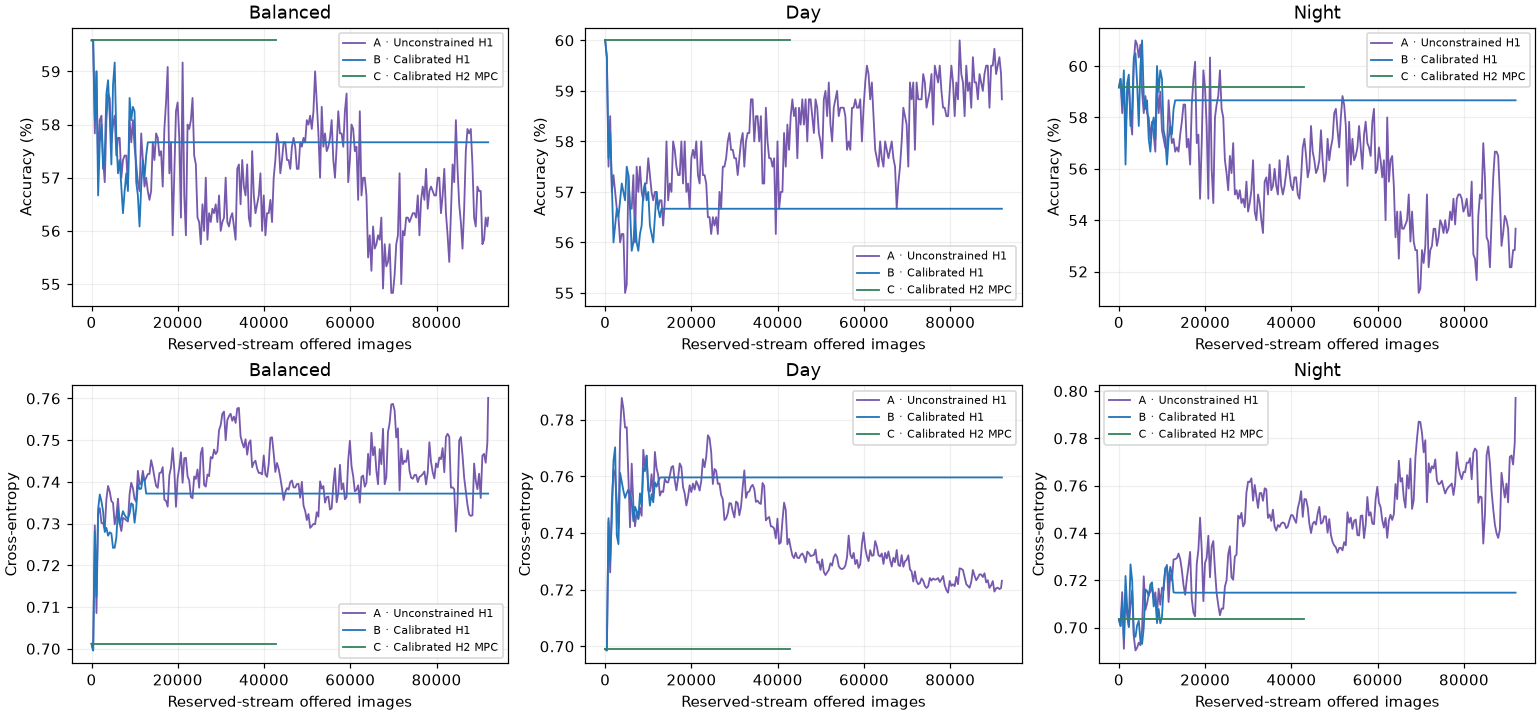



## Additional representation metrics

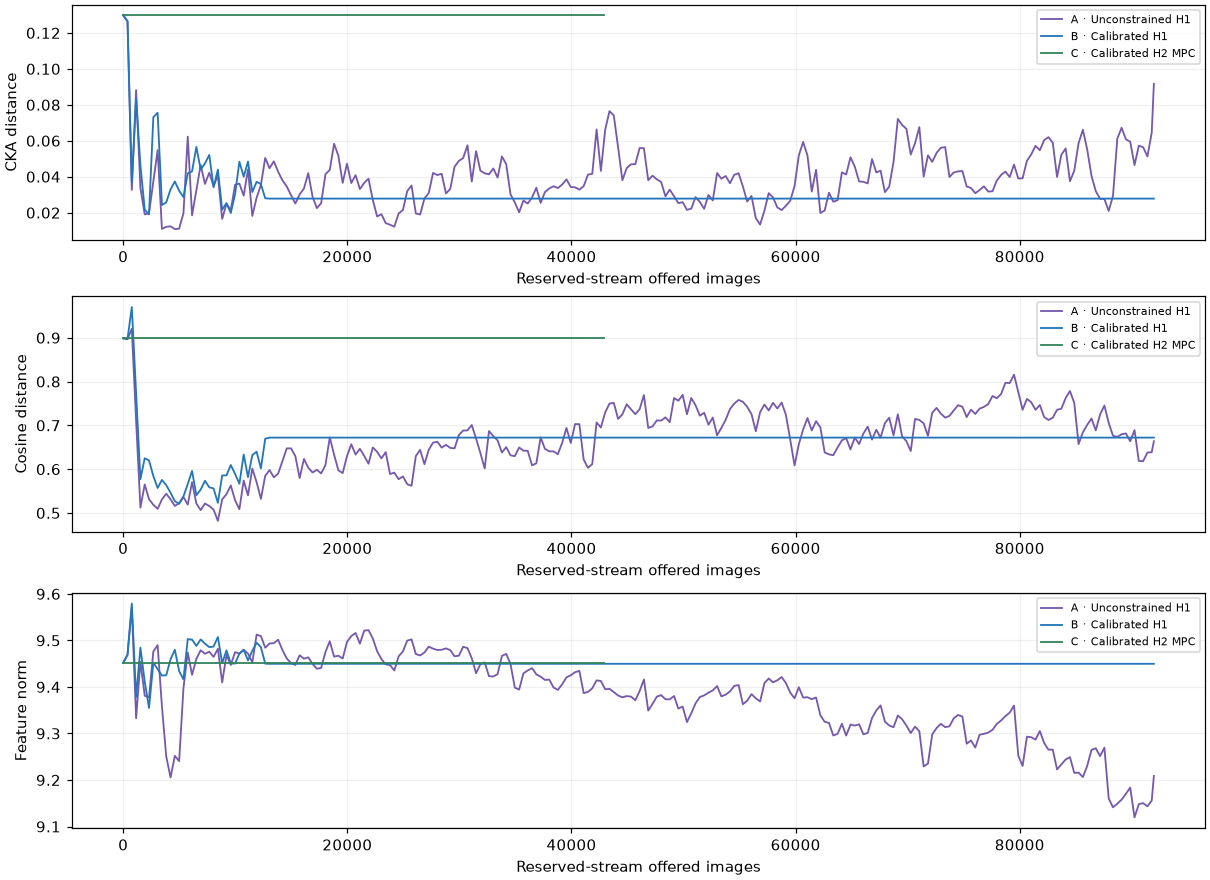



## Secondary evaluation health

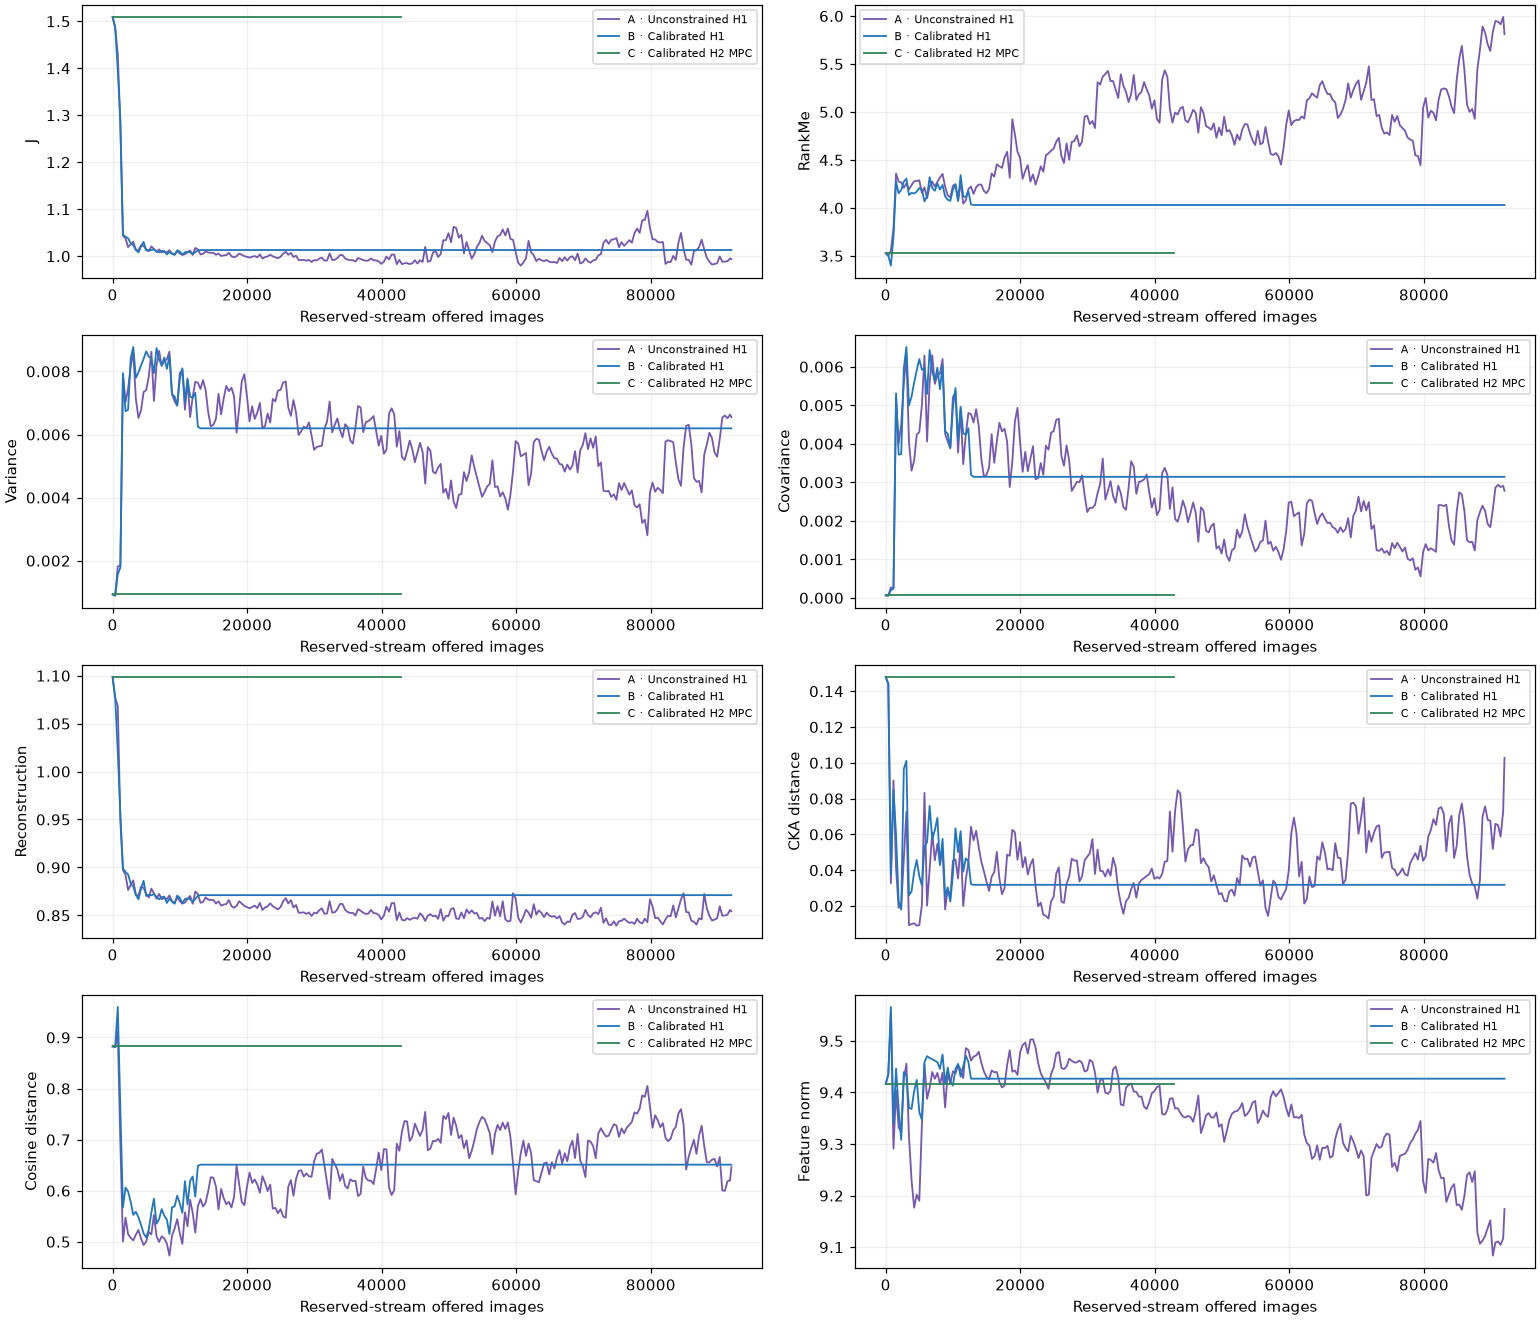



## Actual health versus pre-action causal floors

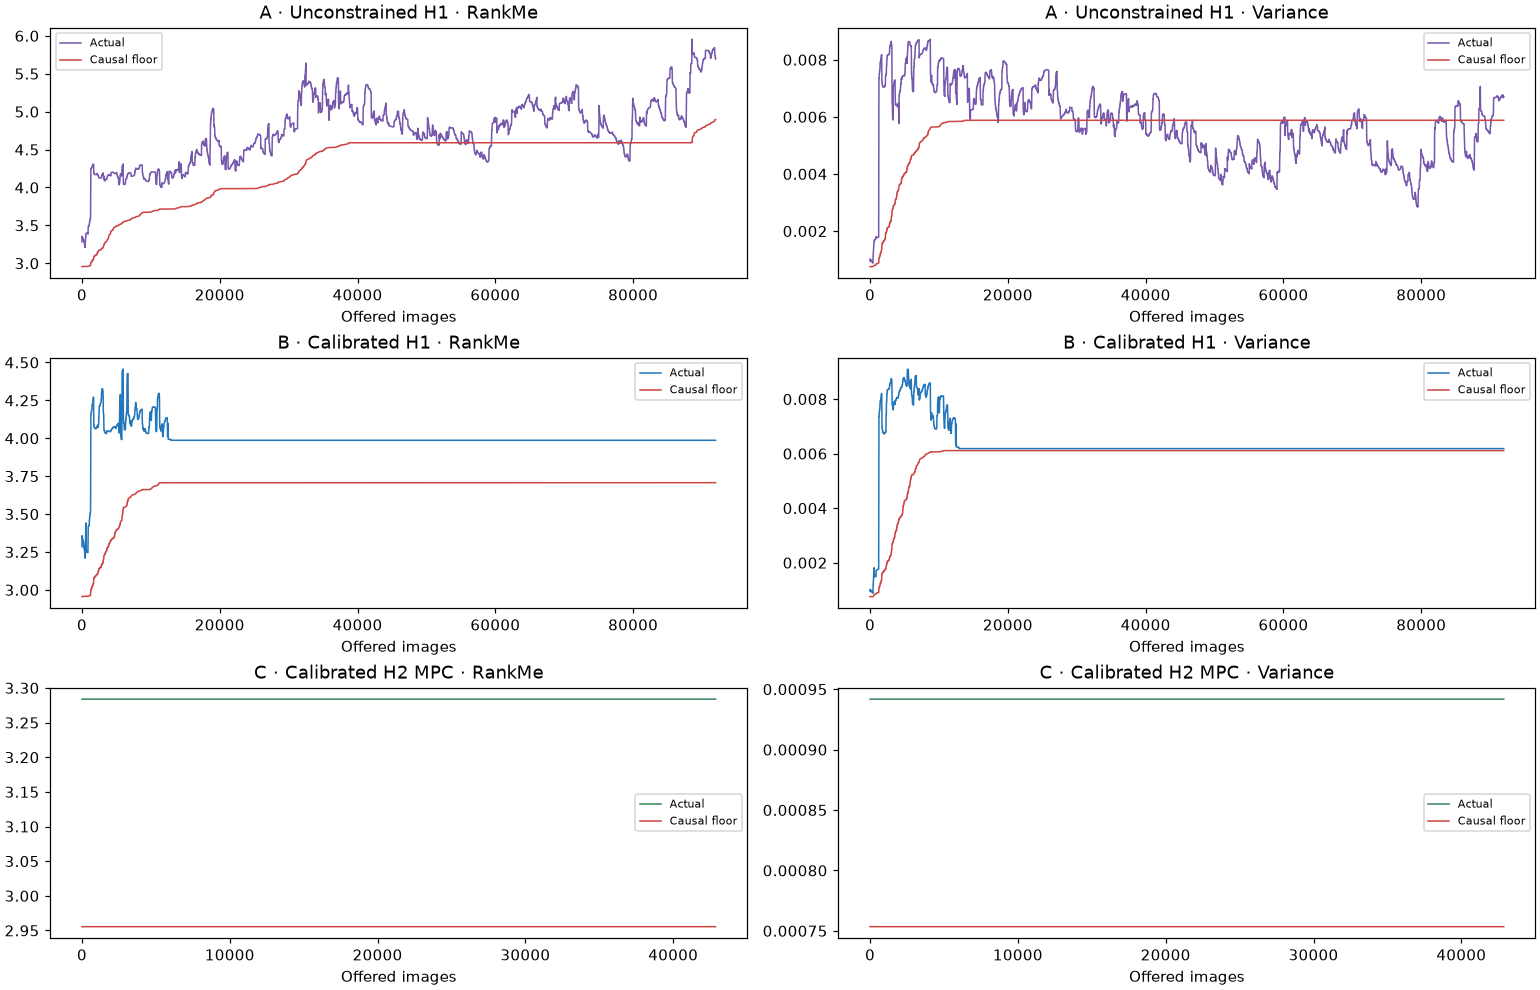



## Prequential chosen-action bound coverage

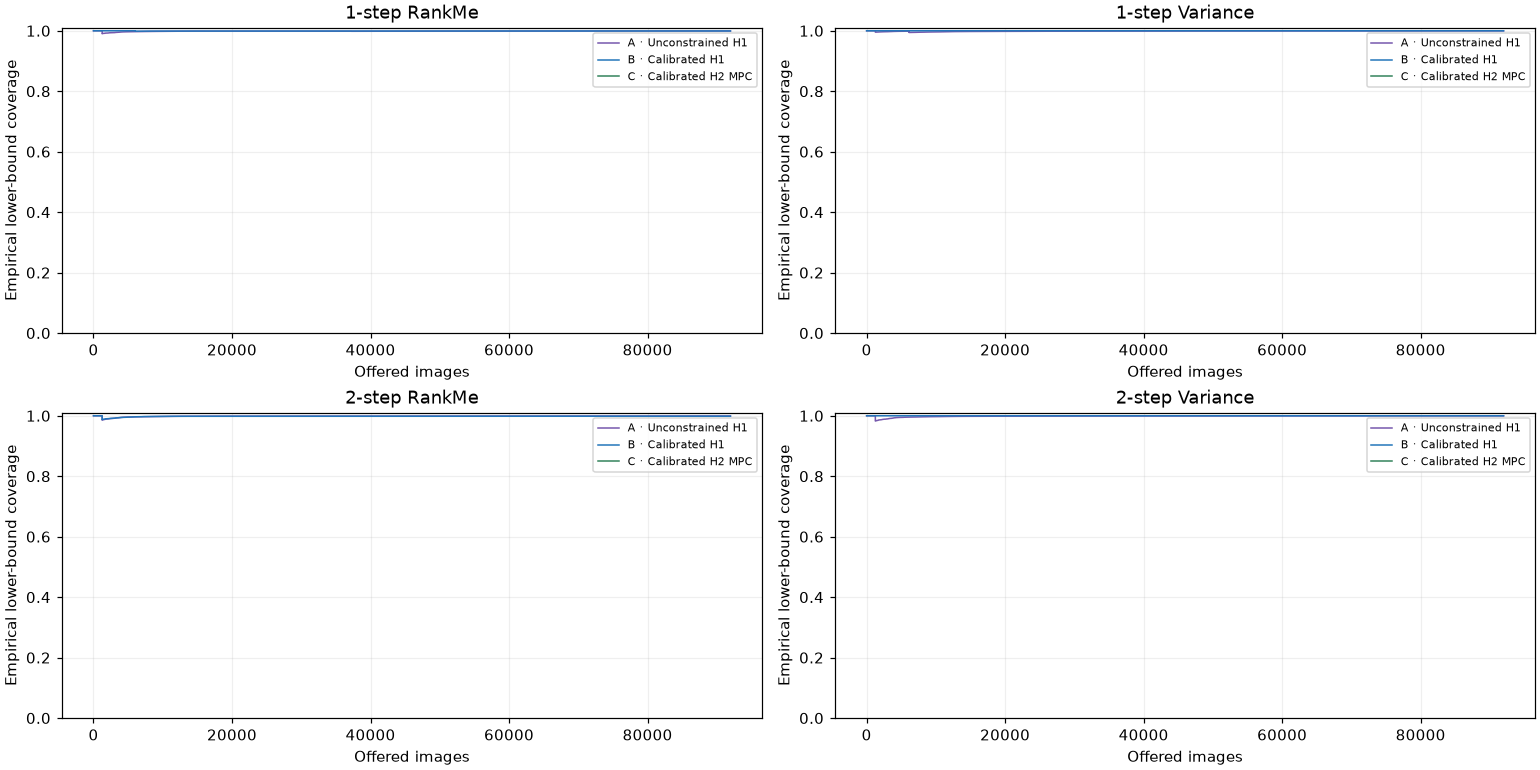

One-step positive updates; two-step nontrivial actual pairs. No claim of policy-independent joint online coverage.

## Filtering, recovery and actual violations

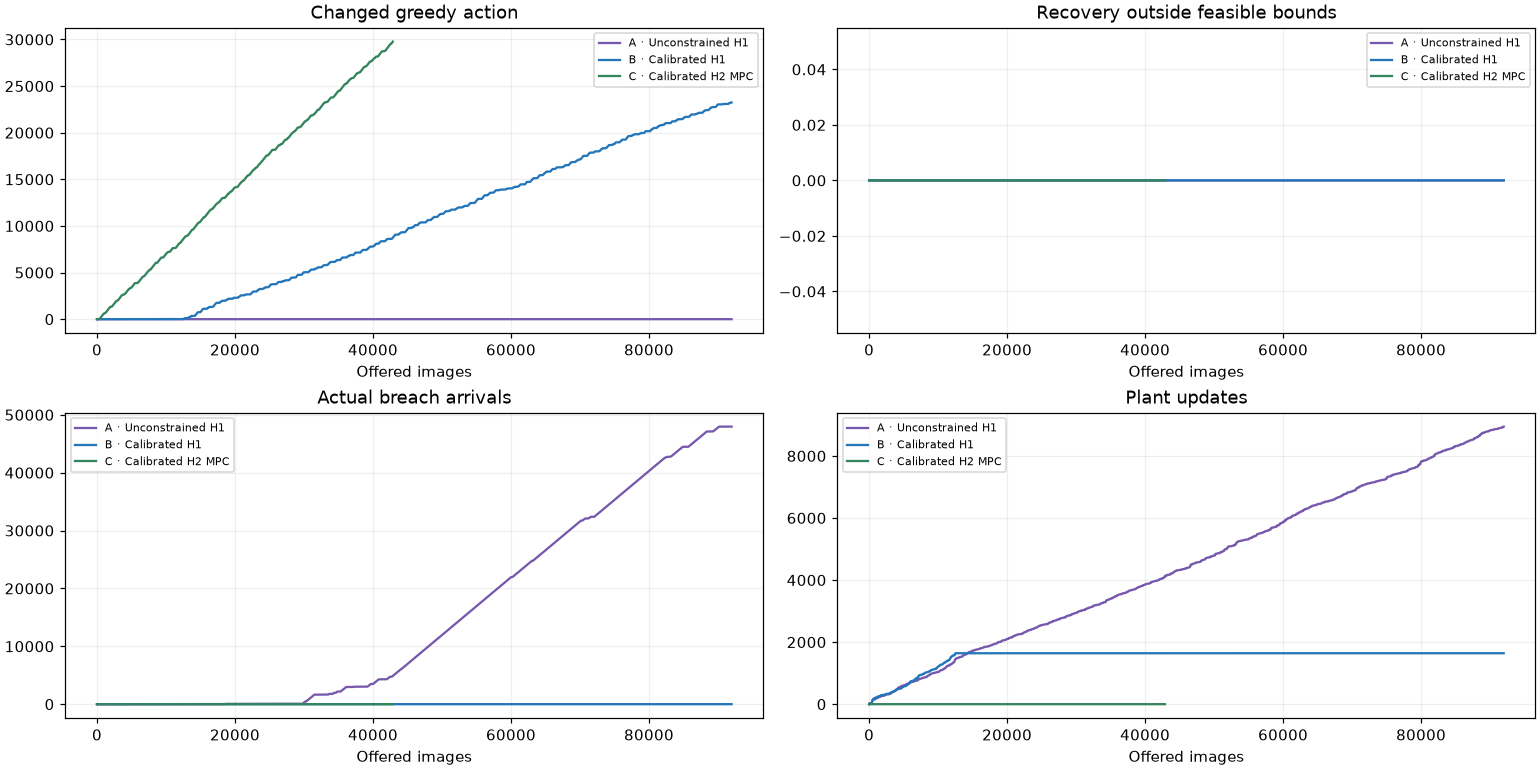



## Direct performance-head prediction error

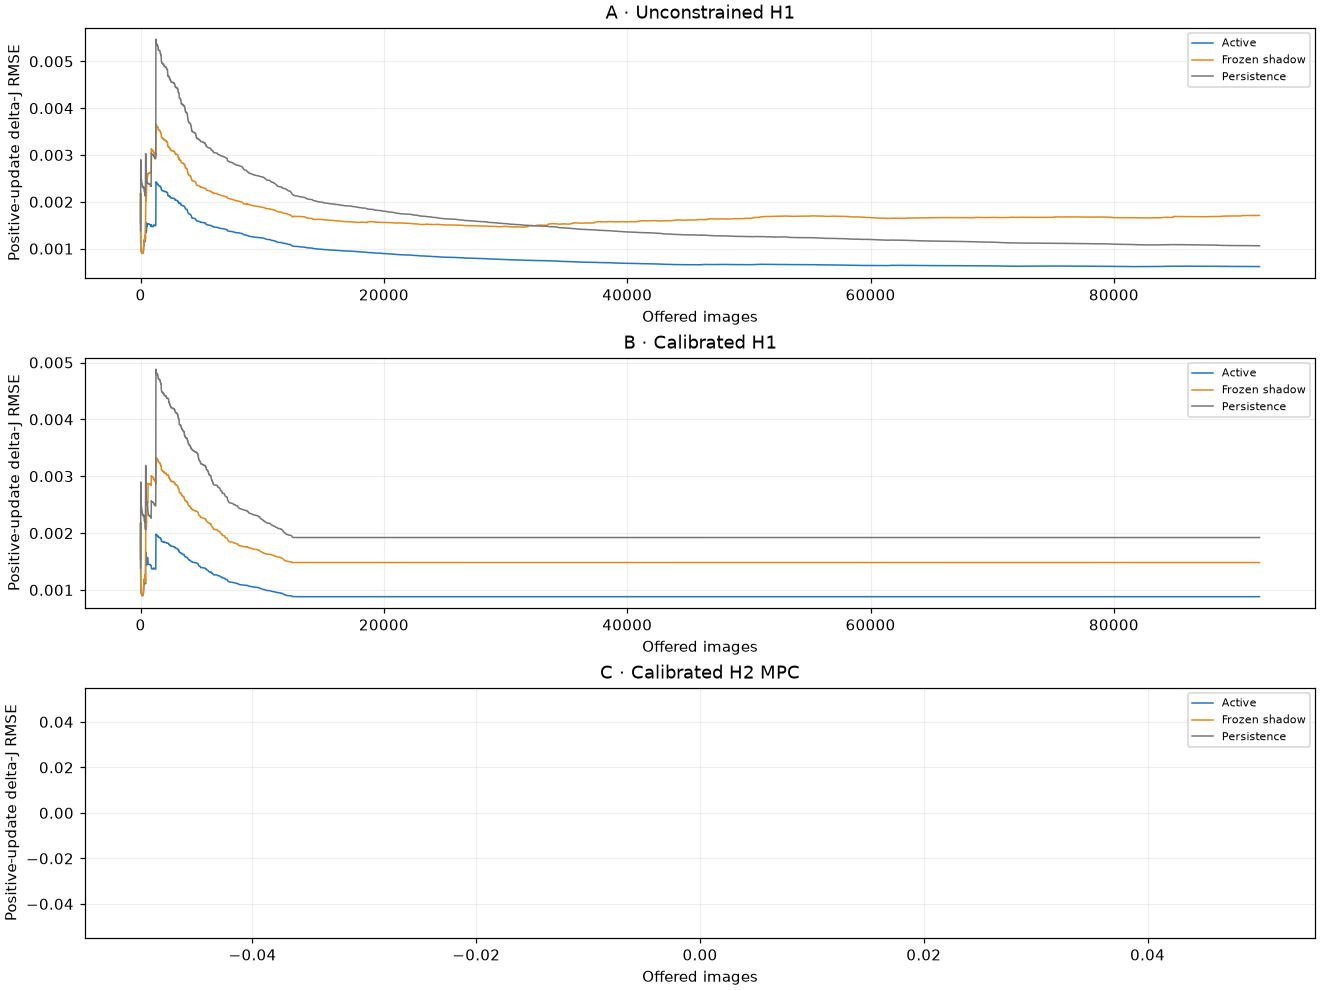

